# Can Saliency Maps Flag Chest Radiograph Classifier Errors at a New Hospital? An External Validation Study
## Feature Extraction and Classical ML
## Aashish Chapagai (Last Edited: September 2026)

In [1]:
import os

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import json
import joblib
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, auc
from sklearn.metrics import classification_report, multilabel_confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

tf.get_logger().setLevel('ERROR')

os.makedirs('models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print(f"Extracting features on {gpus[0].name} with mixed float16 precision.")

Extracting features on /physical_device:GPU:0 with mixed float16 precision.


In [3]:
X_train = np.load('models/X_train.npy', mmap_mode='r')
X_test = np.load('models/X_test.npy', mmap_mode='r')
Y_train = np.load('models/Y_train.npy')
Y_test = np.load('models/Y_test.npy')
disease_classes = np.load('models/disease_classes.npy').tolist()
train_patient_ids = np.load('models/train_patient_ids.npy', allow_pickle=True)
test_patient_ids = np.load('models/test_patient_ids.npy', allow_pickle=True)

IMG_SIZE = X_train.shape[1]
EXTRACT_BATCH_SIZE = 64
SEED = 42
VAL_FRACTION = 0.15
N_BOOTSTRAP = 1000
RF_TREES = 300
RF_MAX_DEPTH = 20
SVM_C = 1.0
SVM_MAX_ITER = 5000
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

print(f"Loaded {X_train.shape[0]} training and {X_test.shape[0]} test images at {IMG_SIZE}px ({X_train.dtype}).")
print(f"Predicting {len(disease_classes)} disease classes.")

shared_patients = set(train_patient_ids).intersection(test_patient_ids)
print(f"Patients appearing in both train and test: {len(shared_patients)}")

Loaded 90286 training and 21834 test images at 320px (uint8).
Predicting 14 disease classes.
Patients appearing in both train and test: 0


In [4]:
gss_val = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
tr_sub_idx, val_sub_idx = next(gss_val.split(np.zeros(len(Y_train)), Y_train, groups=train_patient_ids))

tr_sub_idx = np.sort(tr_sub_idx)
val_sub_idx = np.sort(val_sub_idx)
Y_tr, Y_val = Y_train[tr_sub_idx], Y_train[val_sub_idx]
print(f"Training on {len(tr_sub_idx)} images, validating on {len(val_sub_idx)}.")

Training on 76491 images, validating on 13795.


In [5]:
cnn = tf.keras.models.load_model('models/cnn_base.keras', compile=False)
feature_extractor = tf.keras.Model(cnn.input, cnn.get_layer('gap').output, name='densenet121_features')
print(f"Pooled DenseNet features: {feature_extractor.output_shape[1]} dimensions per image.")

def extract_features(source, indices, batch_size=EXTRACT_BATCH_SIZE):
    def read(batch):
        return np.asarray(source[batch])

    def fetch(batch):
        images = tf.numpy_function(read, [batch], tf.uint8)
        images.set_shape([None, IMG_SIZE, IMG_SIZE, 1])
        return images

    rows = tf.data.Dataset.from_tensor_slices(indices.astype(np.int64)).batch(batch_size)
    batches = rows.map(fetch, num_parallel_calls=AUTOTUNE, deterministic=True)
    flipped_batches = batches.map(tf.image.flip_left_right, num_parallel_calls=AUTOTUNE, deterministic=True)
    upright = feature_extractor.predict(batches.prefetch(AUTOTUNE), verbose=0).astype(np.float32)
    flipped = feature_extractor.predict(flipped_batches.prefetch(AUTOTUNE), verbose=0).astype(np.float32)
    return (upright + flipped) / 2.0

print("\nExtracting features from the training split.")
train_features = extract_features(X_train, tr_sub_idx)
print("Extracting features from the validation split.")
val_features = extract_features(X_train, val_sub_idx)
print("Extracting features from the test split.")
test_features = extract_features(X_test, np.arange(len(Y_test)))

Pooled DenseNet features: 1024 dimensions per image.

Extracting features from the training split.
Extracting features from the validation split.
Extracting features from the test split.


In [6]:
feature_scaler = StandardScaler()
train_features = feature_scaler.fit_transform(train_features)
val_features = feature_scaler.transform(val_features)
test_features = feature_scaler.transform(test_features)

joblib.dump(feature_scaler, 'models/feature_scaler.pkl')
np.save('models/features_train.npy', train_features)
np.save('models/features_val.npy', val_features)
np.save('models/features_test.npy', test_features)
print(f"Standardised {train_features.shape[1]} features and saved the scaler.")

Standardised 1024 features and saved the scaler.


In [7]:
def sweep(score, truth):
    order = np.argsort(-score, kind='stable')
    return score[order], np.cumsum(truth[order]), float(truth.sum())

def cut_point(sorted_score, k):
    if k >= len(sorted_score):
        return float(sorted_score[-1]) - 1e-6
    return float(0.5 * (sorted_score[k - 1] + sorted_score[k]))

def tune_macro_thresholds(y_true, y_score, n_bootstrap=25, seed=SEED):
    y_true = y_true.astype(np.int8)
    rng = np.random.default_rng(seed)
    n, n_classes = y_true.shape
    chosen = np.full(n_classes, np.inf)
    for c in range(n_classes):
        picks = []
        for draw in range(n_bootstrap):
            rows = np.arange(n) if draw == 0 else rng.choice(n, n, True)
            scores, running_tp, positives = sweep(y_score[rows, c], y_true[rows, c])
            if positives == 0:
                continue
            k = np.arange(1, len(scores) + 1)
            best = int(np.argmax(2 * running_tp / (k + positives))) + 1
            picks.append(cut_point(scores, best))
        if picks:
            chosen[c] = float(np.median(picks))
    return chosen

def tune_micro_thresholds(y_true, y_score, start, rounds=4):
    y_true = y_true.astype(np.int8)
    thresholds = start.copy()
    n_classes = y_true.shape[1]
    sweeps = [sweep(y_score[:, c], y_true[:, c]) for c in range(n_classes)]
    for _ in range(rounds):
        pred = (y_score > thresholds).astype(np.int8)
        for c in range(n_classes):
            rest = [j for j in range(n_classes) if j != c]
            tp = int((pred[:, rest] * y_true[:, rest]).sum())
            fp = int((pred[:, rest] * (1 - y_true[:, rest])).sum())
            fn = int(((1 - pred[:, rest]) * y_true[:, rest]).sum())
            scores, running_tp, positives = sweeps[c]
            k = np.arange(1, len(scores) + 1)
            micro = 2 * (tp + running_tp) / ((2 * tp + fp + fn) + k + positives)
            thresholds[c] = cut_point(scores, int(np.argmax(micro)) + 1)
            pred[:, c] = (y_score[:, c] > thresholds[c]).astype(np.int8)
    return thresholds

def tune_hamming_thresholds(y_true, y_score):
    y_true = y_true.astype(np.int8)
    thresholds = np.full(y_true.shape[1], np.inf)
    for c in range(y_true.shape[1]):
        scores, running_tp, positives = sweep(y_score[:, c], y_true[:, c])
        k = np.arange(1, len(scores) + 1)
        errors = (k - running_tp) + (positives - running_tp)
        best = int(np.argmin(errors))
        if errors[best] < positives:
            thresholds[c] = cut_point(scores, best + 1)
    return thresholds

def count_metrics(y_true, y_pred):
    y_true, y_pred = y_true.astype(bool), y_pred.astype(bool)
    tp = (y_true & y_pred).sum(axis=0).astype(float)
    fp = (~y_true & y_pred).sum(axis=0).astype(float)
    fn = (y_true & ~y_pred).sum(axis=0).astype(float)

    def ratio(a, b):
        return np.divide(a, b, out=np.zeros_like(a), where=b > 0)

    return {
        'Hamming loss': (fp.sum() + fn.sum()) / y_true.size,
        'Macro F1': ratio(2 * tp, 2 * tp + fp + fn).mean(),
        'Micro F1': 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1.0),
        'Macro precision': ratio(tp, tp + fp).mean(),
        'Macro recall': ratio(tp, tp + fn).mean(),
        'Micro precision': tp.sum() / max(tp.sum() + fp.sum(), 1.0),
        'Micro recall': tp.sum() / max(tp.sum() + fn.sum(), 1.0),
    }

def patient_bootstrap(y_true, y_score, predictions, groups, n_bootstrap=N_BOOTSTRAP, seed=SEED):
    _, inverse = np.unique(groups, return_inverse=True)
    members = np.split(np.argsort(inverse, kind='stable'), np.cumsum(np.bincount(inverse))[:-1])
    rng = np.random.default_rng(seed)
    samples = {}
    for _ in range(n_bootstrap):
        rows = np.concatenate([members[g] for g in rng.integers(0, len(members), len(members))])
        t, p = y_true[rows], y_score[rows]
        if t.sum(axis=0).min() == 0:
            continue
        per_class = roc_auc_score(t, p, average=None)
        values = {}
        values['Macro ROC-AUC'] = per_class.mean()
        values['Micro ROC-AUC'] = roc_auc_score(t, p, average='micro')
        values['Macro PR-AUC'] = average_precision_score(t, p, average='macro')
        values.update({f"AUC {name}": value for name, value in zip(disease_classes, per_class)})
        for label, y_pred in predictions.items():
            values.update({f"{label} {name}": value for name, value in count_metrics(t, y_pred[rows]).items()})
        for name, value in values.items():
            samples.setdefault(name, []).append(value)
    return {name: np.percentile(values, [2.5, 97.5]) for name, values in samples.items()}

In [8]:
descriptions = {
    'macro-F1': "operating point tuned for macro-F1:",
    'micro-F1': "operating point tuned for micro-F1:",
    'Hamming': "operating point minimising Hamming loss:",
}

def evaluate_model(name, val_scores, test_scores):
    macro_thresholds = tune_macro_thresholds(Y_val, val_scores)
    micro_thresholds = tune_micro_thresholds(Y_val, val_scores, macro_thresholds)
    hamming_thresholds = tune_hamming_thresholds(Y_val, val_scores)
    operating_points = {
        'macro-F1': macro_thresholds,
        'micro-F1': micro_thresholds,
        'Hamming': hamming_thresholds,
    }
    predictions = {label: (test_scores > t).astype(int) for label, t in operating_points.items()}

    print(f"\nBootstrapping {N_BOOTSTRAP} patient-level resamples for 95% confidence intervals.")
    ci = patient_bootstrap(Y_test, test_scores, predictions, test_patient_ids)
    per_class_auc = roc_auc_score(Y_test, test_scores, average=None)

    threshold_free = {
        'Macro ROC-AUC': roc_auc_score(Y_test, test_scores, average='macro'),
        'Micro ROC-AUC': roc_auc_score(Y_test, test_scores, average='micro'),
        'Macro PR-AUC': average_precision_score(Y_test, test_scores, average='macro'),
    }

    print(f"\n{name} threshold-free metrics (95% CI):")
    for metric, value in threshold_free.items():
        print(f"{metric}: {value:.4f} [{ci[metric][0]:.4f}, {ci[metric][1]:.4f}]")

    print(f"\n{name} per-class ROC-AUC (95% CI):")
    for c, disease in enumerate(disease_classes):
        low, high = ci[f"AUC {disease}"]
        print(f"  {disease:<20}{per_class_auc[c]:.4f} [{low:.4f}, {high:.4f}]   {int(Y_test[:, c].sum()):>5} positives")

    point_results = {}
    for label, y_pred in predictions.items():
        point_results[label] = count_metrics(Y_test, y_pred)
        print(f"\n{name} {descriptions[label]}")
        for metric, value in point_results[label].items():
            low, high = ci[f"{label} {metric}"]
            print(f"{metric}: {value:.4f} [{low:.4f}, {high:.4f}]")
    
    return {
        'test_scores': test_scores,
        'predictions': predictions,
        'per_class_auc': per_class_auc,
        'threshold_free': threshold_free,
        'point_results': point_results,
    }

In [9]:
def stack_positive(proba):
    return np.column_stack([column[:, 1] for column in proba])

print(f"\nFitting a random forest with {RF_TREES} trees at depth {RF_MAX_DEPTH}.")
random_forest = RandomForestClassifier(n_estimators=RF_TREES, max_depth=RF_MAX_DEPTH, n_jobs=-1, random_state=SEED)
random_forest.fit(train_features, Y_tr)
joblib.dump(random_forest, 'models/random_forest.pkl', compress=3)
print("Saved the random forest to models/random_forest.pkl.")
    
rf_val_scores = stack_positive(random_forest.predict_proba(val_features))
rf_test_scores = stack_positive(random_forest.predict_proba(test_features))
np.save('models/rf_test_probabilities.npy', rf_test_scores)

rf = evaluate_model('Random forest', rf_val_scores, rf_test_scores)


Fitting a random forest with 300 trees at depth 20.
Saved the random forest to models/random_forest.pkl.

Bootstrapping 1000 patient-level resamples for 95% confidence intervals.

Random forest threshold-free metrics (95% CI):
Macro ROC-AUC: 0.8403 [0.8312, 0.8477]
Micro ROC-AUC: 0.8881 [0.8846, 0.8913]
Macro PR-AUC: 0.2840 [0.2634, 0.3058]

Random forest per-class ROC-AUC (95% CI):
  Atelectasis         0.8265 [0.8154, 0.8369]    2251 positives
  Cardiomegaly        0.9124 [0.8963, 0.9265]     540 positives
  Consolidation       0.7993 [0.7828, 0.8161]     847 positives
  Edema               0.9010 [0.8859, 0.9160]     484 positives
  Effusion            0.8943 [0.8853, 0.9029]    2618 positives
  Emphysema           0.9270 [0.9100, 0.9411]     502 positives
  Fibrosis            0.8001 [0.7735, 0.8262]     332 positives
  Hernia              0.8635 [0.7647, 0.9413]      33 positives
  Infiltration        0.7076 [0.6948, 0.7197]    3893 positives
  Mass                0.8716 [0.8556,

In [10]:
print(f"\nFitting a one-vs-rest linear SVM at C={SVM_C}.")
linear_svm = LinearSVC(C=SVM_C, dual=False, class_weight='balanced', max_iter=SVM_MAX_ITER, random_state=SEED)
support_vector_machine = OneVsRestClassifier(linear_svm, n_jobs=-1)
support_vector_machine.fit(train_features, Y_tr)
joblib.dump(support_vector_machine, 'models/linear_svm.pkl')
print("Saved the linear SVM to models/linear_svm.pkl.")

svm_val_scores = support_vector_machine.decision_function(val_features)
svm_test_scores = support_vector_machine.decision_function(test_features)
np.save('models/svm_test_scores.npy', svm_test_scores)

svm = evaluate_model('Linear SVM', svm_val_scores, svm_test_scores)


Fitting a one-vs-rest linear SVM at C=1.0.
Saved the linear SVM to models/linear_svm.pkl.

Bootstrapping 1000 patient-level resamples for 95% confidence intervals.

Linear SVM threshold-free metrics (95% CI):
Macro ROC-AUC: 0.8261 [0.8173, 0.8340]
Micro ROC-AUC: 0.8586 [0.8551, 0.8623]
Macro PR-AUC: 0.2393 [0.2270, 0.2602]

Linear SVM per-class ROC-AUC (95% CI):
  Atelectasis         0.8215 [0.8104, 0.8324]    2251 positives
  Cardiomegaly        0.9053 [0.8885, 0.9199]     540 positives
  Consolidation       0.7866 [0.7696, 0.8037]     847 positives
  Edema               0.8859 [0.8692, 0.9016]     484 positives
  Effusion            0.8901 [0.8810, 0.8987]    2618 positives
  Emphysema           0.9143 [0.8957, 0.9301]     502 positives
  Fibrosis            0.7688 [0.7424, 0.7946]     332 positives
  Hernia              0.8138 [0.7122, 0.8979]      33 positives
  Infiltration        0.7124 [0.7001, 0.7242]    3893 positives
  Mass                0.8540 [0.8363, 0.8703]    1152 posi

In [11]:
with open('models/test_metrics.json') as handle:
    cnn_metrics = json.load(handle)

cnn_threshold_free = {name: entry['value'] for name, entry in cnn_metrics['threshold_free'].items()}
cnn_macro_point = {name: entry['value'] for name, entry in cnn_metrics['operating_points']['macro-F1'].items()}

comparison = {
    'DenseNet-121': {**cnn_threshold_free, **cnn_macro_point},
    'Random forest': {**rf['threshold_free'], **rf['point_results']['macro-F1']},
    'Linear SVM': {**svm['threshold_free'], **svm['point_results']['macro-F1']},
}

print("\nModel comparison at the macro-F1 operating point:")
print(f"{'Metric':<20}{'DenseNet-121':>15}{'Random forest':>15}{'Linear SVM':>15}")
for metric in comparison['DenseNet-121']:
    values = ''.join(f"{comparison[model][metric]:>15.4f}" for model in comparison)
    print(f"{metric:<20}{values}")

with open('models/classical_metrics.json', 'w') as handle:
    json.dump(comparison, handle, indent=2)
print("\nSaved the comparison to models/classical_metrics.json.")


Model comparison at the macro-F1 operating point:
Metric                 DenseNet-121  Random forest     Linear SVM
Macro ROC-AUC                0.8469         0.8403         0.8261
Micro ROC-AUC                0.8892         0.8881         0.8586
Macro PR-AUC                 0.2813         0.2840         0.2393
Hamming loss                 0.0721         0.0770         0.0811
Macro F1                     0.3415         0.3464         0.3115
Micro F1                     0.3921         0.3895         0.3747
Macro precision              0.3193         0.3121         0.2742
Macro recall                 0.3900         0.4153         0.3858
Micro precision              0.3474         0.3301         0.3115
Micro recall                 0.4500         0.4749         0.4703

Saved the comparison to models/classical_metrics.json.


In [12]:
print("\nPer-class performance at the macro-F1 operating point:")
for name, result in (('Random forest', rf), ('Linear SVM', svm)):
    print(f"\n{name}")
    print(classification_report(Y_test, result['predictions']['macro-F1'], target_names=disease_classes, zero_division=0))


Per-class performance at the macro-F1 operating point:

Random forest
                    precision    recall  f1-score   support

       Atelectasis       0.36      0.50      0.42      2251
      Cardiomegaly       0.29      0.44      0.35       540
     Consolidation       0.15      0.41      0.22       847
             Edema       0.26      0.24      0.25       484
          Effusion       0.50      0.66      0.57      2618
         Emphysema       0.48      0.51      0.50       502
          Fibrosis       0.14      0.16      0.15       332
            Hernia       0.48      0.36      0.41        33
      Infiltration       0.37      0.45      0.41      3893
              Mass       0.42      0.46      0.44      1152
            Nodule       0.30      0.41      0.35      1240
Pleural_Thickening       0.21      0.34      0.26       692
         Pneumonia       0.06      0.32      0.11       276
      Pneumothorax       0.35      0.54      0.42       940

         micro avg       0.

In [13]:
for name, result in (('Random forest', rf), ('Linear SVM', svm)):
    print(f"\n{name} sample predictions at the macro-F1 operating point:")
    test_predictions = result['predictions']['macro-F1']
    for i in range(5):
        predicted_names = [disease for j, disease in enumerate(disease_classes) if test_predictions[i, j] == 1]
        actual_names = [disease for j, disease in enumerate(disease_classes) if Y_test[i, j] == 1]
        print(f"Image {i + 1}")
        print(f"  Predicted: {', '.join(predicted_names) or 'No Finding'}")
        print(f"  Actual: {', '.join(actual_names) or 'No Finding'}")


Random forest sample predictions at the macro-F1 operating point:
Image 1
  Predicted: Cardiomegaly
  Actual: Cardiomegaly
Image 2
  Predicted: Cardiomegaly
  Actual: Cardiomegaly, Emphysema
Image 3
  Predicted: Cardiomegaly, Effusion
  Actual: Cardiomegaly, Effusion
Image 4
  Predicted: Nodule
  Actual: No Finding
Image 5
  Predicted: No Finding
  Actual: No Finding

Linear SVM sample predictions at the macro-F1 operating point:
Image 1
  Predicted: Cardiomegaly
  Actual: Cardiomegaly
Image 2
  Predicted: Cardiomegaly
  Actual: Cardiomegaly, Emphysema
Image 3
  Predicted: Cardiomegaly, Effusion
  Actual: Cardiomegaly, Effusion
Image 4
  Predicted: Mass, Nodule
  Actual: No Finding
Image 5
  Predicted: No Finding
  Actual: No Finding


In [14]:
for name, result in (('Random forest', rf), ('Linear SVM', svm)):
    print(f"\n{name} confusion matrices at the macro-F1 operating point:")
    for disease, matrix in zip(disease_classes, multilabel_confusion_matrix(Y_test, result['predictions']['macro-F1'])):
        tn, fp, fn, tp = matrix.ravel()
        print(f"  {disease:<20}TN {tn:>6}  FP {fp:>6}  FN {fn:>6}  TP {tp:>6}")


Random forest confusion matrices at the macro-F1 operating point:
  Atelectasis         TN  17562  FP   2021  FN   1116  TP   1135
  Cardiomegaly        TN  20721  FP    573  FN    303  TP    237
  Consolidation       TN  19035  FP   1952  FN    497  TP    350
  Edema               TN  21015  FP    335  FN    368  TP    116
  Effusion            TN  17481  FP   1735  FN    896  TP   1722
  Emphysema           TN  21057  FP    275  FN    244  TP    258
  Fibrosis            TN  21166  FP    336  FN    278  TP     54
  Hernia              TN  21788  FP     13  FN     21  TP     12
  Infiltration        TN  15020  FP   2921  FN   2144  TP   1749
  Mass                TN  19931  FP    751  FN    618  TP    534
  Nodule              TN  19424  FP   1170  FN    736  TP    504
  Pleural_Thickening  TN  20238  FP    904  FN    456  TP    236
  Pneumonia           TN  20278  FP   1280  FN    188  TP     88
  Pneumothorax        TN  19929  FP    965  FN    431  TP    509

Linear SVM confusion m

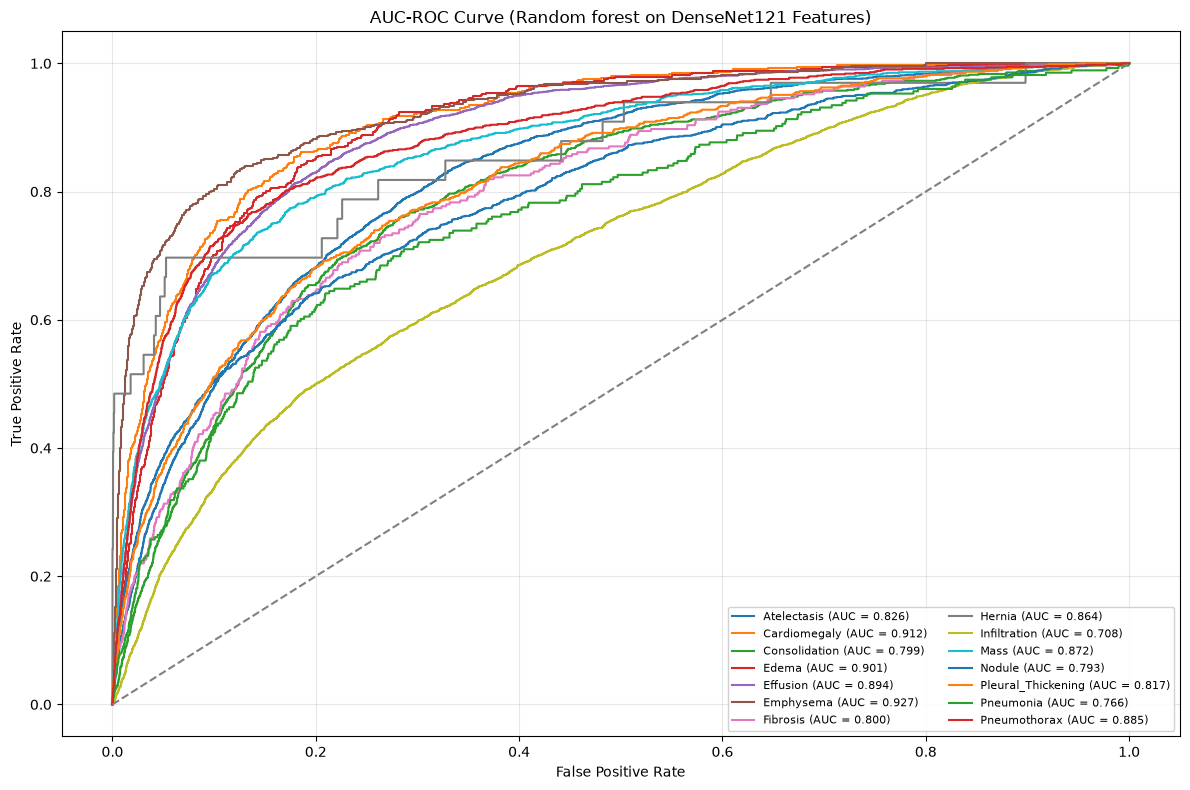

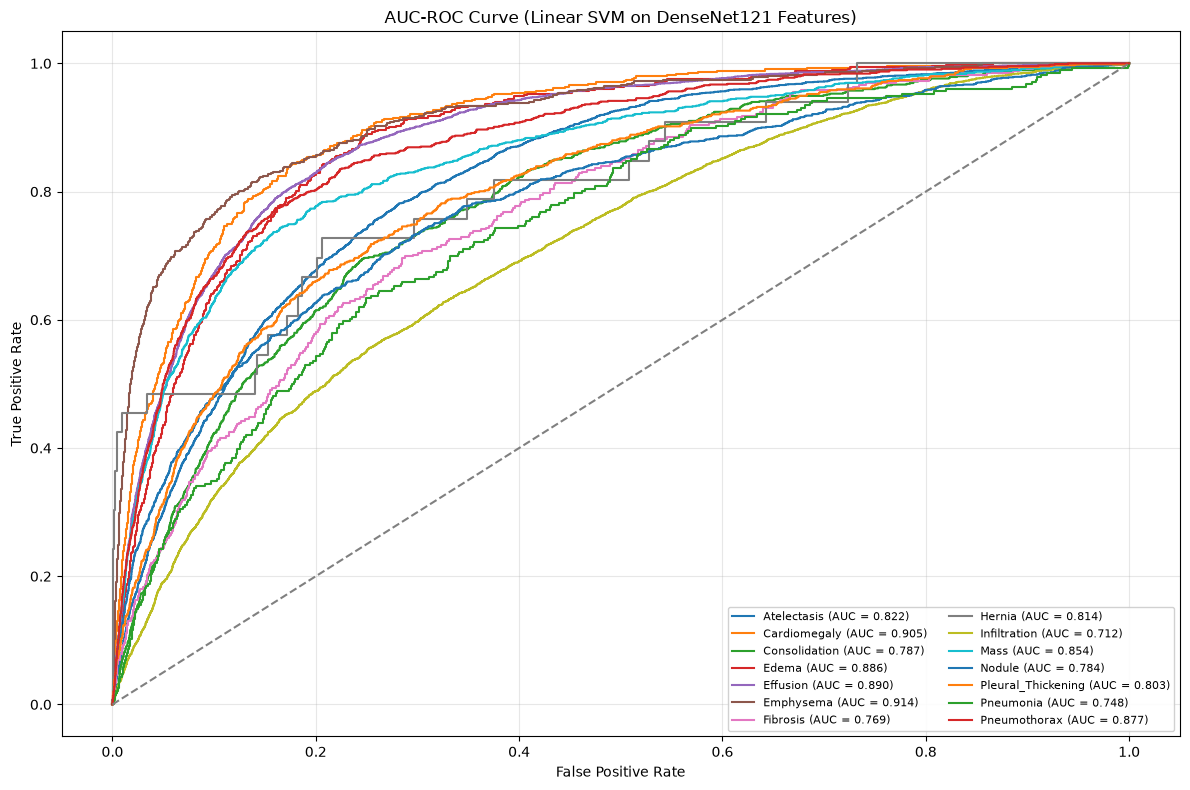

In [15]:
for name, result in (('Random forest', rf), ('Linear SVM', svm)):
    plt.figure(figsize=(12, 8))
    for c, disease in enumerate(disease_classes):
        fpr, tpr, _ = roc_curve(Y_test[:, c], result['test_scores'][:, c])
        plt.plot(fpr, tpr, label=f"{disease} (AUC = {auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'AUC-ROC Curve ({name} on DenseNet121 Features)')
    plt.legend(loc='lower right', fontsize=8, ncol=2, framealpha=0.9)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"figures/{name.lower().replace(' ', '_')}_roc_curves.png", dpi=300, bbox_inches='tight')
    plt.show()